# 05 — Esboço do Dashboard em Python

### Projeto Varejo · As 20 perguntas de negócio em pandas e matplotlib

| Campo | Valor |
|---|---|
| **Notebook** | `notebooks/05-esboco-dashboard-python.ipynb` |
| **Entrada** | `data/processed/varejo_limpo.parquet` — gerada pelo `03-diagnostico.ipynb` (v1.1) |
| **Saídas** | Tabelas e gráficos na tela. Opcional: figuras PNG em `reports/imagens/05-esboco/` |
| **Equivalente** | `dashboards/excel/esboco-dashboard-excel.xlsx` — mesmas perguntas, filtros e números |
| **Bibliotecas** | `pandas`, `numpy`, `matplotlib` (já instaladas no ambiente `varejo`) |
| **Compatibilidade** | Windows 10 e Ubuntu · pandas 2.x e 3.x · Python 3.11+ |
| **Versão** | 1.0 — 30/10/2026 |

**Dado fictício.** O objetivo é demonstrar o método de análise, não tirar conclusões de mercado.

## Como este notebook está organizado

Cada pergunta tem sempre as mesmas quatro partes, identificadas por nome:

| Parte | Nome no código | O que é |
|---|---|---|
| Enunciado | `Pergunta N` | A pergunta, como ler o resultado e o visual escolhido |
| Tabela | `TABELA TN` | O cálculo em pandas, comentado linha a linha |
| Gráfico | `GRÁFICO GN` | O visual em matplotlib, comentado linha a linha |
| Conclusão | `Sua conclusão — pergunta N` | Célula de texto para **você** escrever o que encontrou |

No final, a seção **Conferência** compara os números com o esboço em Excel. Os dois precisam bater:
é a prova de que as ferramentas convergem.

## Regras de filtro (as mesmas do Excel)

- **Pergunta 7** ignora as 260 vendas com preço imputado (`preco_origem = imputado_mediana_categoria`).
- **Perguntas 18 a 20** ignoram as 69 vendas com desconto imputado (`desconto_origem = imputado_mediana`).
- **"Não informado"** (canal) e **"NI"** (UF) aparecem como grupo próprio, em cinza, e entram no faturamento.

## Índice

| Bloco | Perguntas |
|---|---|
| 1 · Receita e Tendência | [1](#p1) · [2](#p2) · [3](#p3) · [4](#p4) |
| 2 · Mix de Categorias | [5](#p5) · [6](#p6) · [7](#p7) · [8](#p8) |
| 3 · Canais de Venda | [9](#p9) · [10](#p10) · [11](#p11) |
| 4 · Geografia | [12](#p12) · [13](#p13) · [14](#p14) |
| 5 · Clientes | [15](#p15) · [16](#p16) · [17](#p17) |
| 6 · Preço e Desconto | [18](#p18) · [19](#p19) · [20](#p20) |
| Fechamento | [Conferência com o Excel](#conferencia) |

## Como executar

**Windows 10 — Anaconda Prompt:** `conda activate varejo` → `cd /d C:\Git\Projeto-Varejo` → `jupyter lab`
**Ubuntu — terminal:** `conda activate varejo` → `cd ~/Git/Projeto-Varejo` → `jupyter lab`

Abra o notebook e use *Run → Run All Cells*.

---
## 0. Preparação

### 0.1 Bibliotecas

In [14]:
# =====================================================================
# 0.1 BIBLIOTECAS
# =====================================================================
import logging                                   # controla mensagens de aviso das bibliotecas
from pathlib import Path                         # monta caminhos que funcionam no Windows e no Ubuntu

import numpy as np                               # cálculos numéricos (correlação, regressão)
import pandas as pd                              # tabelas e agregações
import matplotlib                                # biblioteca de gráficos (para conferir a versão)
import matplotlib.pyplot as plt                  # interface de desenho dos gráficos
from matplotlib.colors import LinearSegmentedColormap  # cria escalas de cor de um só tom
from matplotlib.ticker import FuncFormatter      # formata os números dos eixos no padrão brasileiro

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # silencia aviso de fonte ausente

print(f"pandas     {pd.__version__}")             # mostra a versão do pandas em uso
print(f"numpy      {np.__version__}")             # mostra a versão do numpy em uso
print(f"matplotlib {matplotlib.__version__}")     # mostra a versão do matplotlib em uso

pandas     2.2.2
numpy      1.26.4
matplotlib 3.9.2


### 0.2 Caminhos e parâmetros

Tudo o que pode mudar fica nesta célula. Para salvar as figuras em PNG, troque `SALVAR_FIGURAS`
para `True`.

In [17]:
# =====================================================================
# 0.2 CAMINHOS E PARÂMETROS
# =====================================================================
RAIZ = Path.cwd()                                # pasta onde o Jupyter foi aberto
if RAIZ.name == "notebooks":                     # se foi aberto dentro de notebooks/...
    RAIZ = RAIZ.parent                           # ...sobe um nível para a raiz do projeto

ARQ_BASE = RAIZ / "data" / "processed" / "varejo_limpo.parquet"   # base limpa gerada pelo 03
PASTA_FIGURAS = RAIZ / "reports" / "imagens" / "05-esboco"        # destino opcional dos PNG

SALVAR_FIGURAS = False                           # True = grava cada gráfico como PNG
MASSA_MINIMA_UF = 15                             # vendas mínimas para comparar uma UF (pergunta 14)
RFV_CAMPEOES = 10                                # soma RFV mínima para "Campeões" (pergunta 17)
RFV_LEAIS = 7                                    # soma RFV mínima para "Leais"
RFV_ATENCAO = 5                                  # soma RFV mínima para "Atenção"; abaixo = "Em risco"

PRECO_IMPUTADO = "imputado_mediana_categoria"    # rótulo das 260 vendas com preço estimado
DESCONTO_IMPUTADO = "imputado_mediana"           # rótulo das 69 vendas com desconto estimado
SEM_CANAL = "Não informado"                      # rótulo das vendas sem canal
SEM_UF = "NI"                                    # rótulo das vendas sem UF

print(f"Raiz do projeto: {RAIZ}")                # confirma a raiz encontrada
print(f"Base limpa     : {ARQ_BASE}")            # confirma o caminho da base
print(f"Existe         : {ARQ_BASE.exists()}")   # deve ser True; se False, rode o 03-diagnostico

Raiz do projeto: C:\Users\Kleber\Desktop\testando_notebook
Base limpa     : C:\Users\Kleber\Desktop\testando_notebook\data\processed\varejo_limpo.parquet
Existe         : True


### 0.3 Carregar a base limpa

In [20]:
# =====================================================================
# 0.3 CARREGAR A BASE LIMPA
# =====================================================================
if not ARQ_BASE.exists():                        # sem a base, nada funciona: avisa e para
    raise FileNotFoundError("Base limpa não encontrada. Execute antes o notebooks/03-diagnostico.ipynb.")  # interrompe com mensagem clara

df = pd.read_parquet(ARQ_BASE)                   # lê o Parquet: tipos e datas vêm preservados

FATURAMENTO = df["valor_total"].sum()            # faturamento total, usado em vários percentuais

print(f"Vendas      : {len(df)}")                # esperado: 1000
print(f"Colunas     : {df.shape[1]}")            # esperado: 17
print(f"Período     : {df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}")  # esperado: 2024 inteiro
print(f"Faturamento : R$ {FATURAMENTO:,.2f}".replace(",", "§").replace(".", ",").replace("§", "."))  # esperado: R$ 109.344,37
df.head()                                        # mostra as cinco primeiras vendas

Vendas      : 1000
Colunas     : 17
Período     : 01/01/2024 a 31/12/2024
Faturamento : R$ 109.344,37


,id_venda,data,mes,ano,dia,dia_semana,cliente,categoria,canal,uf,quantidade,preco_unit,desconto_pct,valor_total,preco_origem,desconto_origem,valor_origem
0,1,2024-08-08,8,2024,8,Quinta-feira,CLI-0069,Limpeza,Não informado,BA,1,21.67,0.45,50.63,imputado_mediana_categoria,original,original
1,2,2024-11-12,11,2024,12,Terça-feira,CLI-0050,Limpeza,Loja,RJ,4,111.06,4.91,422.43,original,original,original
2,3,2024-09-08,9,2024,8,Domingo,CLI-0149,Padaria,Loja,NI,5,10.73,4.86,51.04,original,original,corrigido_decimal
3,4,2024-04-07,4,2024,7,Domingo,CLI-0044,Bebidas,Não informado,SP,2,87.89,2.87,170.74,original,original,original
4,5,2024-06-27,6,2024,27,Quinta-feira,CLI-0140,Hortifruti,Loja,SP,1,8.10,0.37,8.07,original,reconstruido,original


### 0.4 Funções de apoio: formatação brasileira, cores e estilo

**Cores.** Paleta categórica validada para daltonismo (verificador da skill de visualização,
modo claro: todas as checagens aprovadas). Cada categoria e cada canal tem **sempre a mesma cor**
em todos os gráficos. Ausência ("Não informado", "NI") é sempre cinza. Três das cores têm contraste
baixo sobre o fundo claro: por isso cada gráfico vem acompanhado da sua tabela.

In [23]:
# =====================================================================
# 0.4 FUNÇÕES DE APOIO
# =====================================================================

# ---------- 0.4.1 Formatação de números no padrão brasileiro ----------
def brl(valor, casas=2):  # função: número -> texto em reais
    """Formata em reais: 1234.5 -> 'R$ 1.234,50'."""
    texto = f"{valor:,.{casas}f}"                                   # formato americano: 1,234.50
    return "R$ " + texto.replace(",", "§").replace(".", ",").replace("§", ".")  # troca separadores

def pct(valor, casas=1):  # função: fração -> texto em percentual
    """Formata percentual: 0.123 -> '12,3%'."""
    return f"{valor * 100:.{casas}f}%".replace(".", ",")           # multiplica por 100 e usa vírgula

def num(valor, casas=0):  # função: número -> texto com ponto de milhar
    """Formata número: 1234 -> '1.234'."""
    texto = f"{valor:,.{casas}f}"                                   # formato americano
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")  # troca separadores

EIXO_BRL = FuncFormatter(lambda v, _: brl(v, 0))                    # eixo em reais, sem centavos
EIXO_PCT = FuncFormatter(lambda v, _: pct(v, 0))                    # eixo em percentual, sem decimais
EIXO_NUM = FuncFormatter(lambda v, _: num(v))                       # eixo em números inteiros

def mostrar(tabela, formatos):  # função: exibe tabela formatada
    """Exibe a tabela com números formatados, sem alterar os dados originais."""
    return tabela.style.format(formatos).hide(axis="index")         # aplica formatos e esconde o índice

# ---------- 0.4.2 Cores ----------
AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA = (           # paleta categórica, ordem fixa
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
CINZA = "#b4b2a9"                                                   # cor reservada para ausência
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"                               # tinta principal e secundária
FUNDO, GRADE = "#fcfcfb", "#e6e4de"                                 # superfície e linhas de grade
AZUL_CLARO = "#9ec5f4"                                              # passo claro da rampa azul

ORDEM_CATEGORIAS = (df.groupby("categoria")["valor_total"].sum()    # categorias da maior para a menor...
                    .sort_values(ascending=False).index.tolist())    # ...receita (ordem fixa no notebook)
COR_CATEGORIA = dict(zip(ORDEM_CATEGORIAS,                          # cada categoria ganha um slot fixo
                         [AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA]))  # slots 1 a 7 da paleta, na ordem

ORDEM_CANAIS = (df[df["canal"] != SEM_CANAL].groupby("canal")["valor_total"].sum()  # canais por receita
                .sort_values(ascending=False).index.tolist()) + [SEM_CANAL]          # ausência por último
COR_CANAL = dict(zip(ORDEM_CANAIS, [AZUL, LARANJA, AQUA, AMARELO, CINZA]))          # "Não informado" = cinza

RAMPA_AZUL = LinearSegmentedColormap.from_list("azul", ["#f3f8fe", "#86b6ef", "#2a78d6", "#0d366b"])    # sequencial 1
RAMPA_LARANJA = LinearSegmentedColormap.from_list("laranja", ["#fef3ec", "#f4a77f", "#eb6834", "#8a3412"])  # sequencial 2

MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]  # rótulos

# ---------- 0.4.3 Estilo padrão dos gráficos ----------
plt.rcParams.update({                                               # vale para todos os gráficos
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"],     # Arial no Windows, equivalente no Ubuntu
    "font.size": 10,                                                # tamanho base do texto
    "axes.titlesize": 12, "axes.titleweight": "bold",               # título dos gráficos
    "axes.titlelocation": "left", "axes.titlecolor": TEXTO,         # título alinhado à esquerda
    "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,  # textos secundários
    "axes.edgecolor": GRADE, "axes.facecolor": FUNDO, "figure.facecolor": FUNDO,  # bordas e fundos
    "axes.spines.top": False, "axes.spines.right": False,           # remove molduras de cima e da direita
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,  # grade discreta
    "axes.axisbelow": True,                                         # grade atrás das barras
    "legend.frameon": False,                                        # legenda sem caixa
    "figure.dpi": 100,                                              # resolução na tela
})  # fim do bloco

# ---------- 0.4.4 Salvar figura (opcional) ----------
def salvar(fig, nome):  # função: grava PNG se habilitado
    """Grava o gráfico em PNG quando SALVAR_FIGURAS = True."""
    if SALVAR_FIGURAS:                                              # só grava se o parâmetro pedir
        PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)            # cria a pasta se não existir
        fig.savefig(PASTA_FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")  # grava em alta resolução

print("Funções, cores e estilo prontos.")                           # confirma a execução da célula

Funções, cores e estilo prontos.


---
## Bloco 1 — Receita e Tendência

<a id="p1"></a>
### Pergunta 1 — Evolução mensal da receita

**Pergunta:** a receita está crescendo, caindo ou estável ao longo de 2024?

**Como ler:** a receita de cada mês e a variação em relação à média. Olhe a tendência da linha, não um mês isolado.

**Visual:** linha com marcadores, eixo começando em zero.

In [27]:
# =====================================================================
# TABELA T1 — Receita, vendas e ticket médio por mês
# (também alimenta as perguntas 2 e 3)
# =====================================================================
t1 = (df.groupby("mes")                                   # agrupa as vendas pelo número do mês
        .agg(receita=("valor_total", "sum"),              # soma do valor das vendas
             vendas=("id_venda", "count"))                # quantidade de vendas
        .reset_index())                                   # transforma o mês de índice em coluna
t1["nome"] = t1["mes"].map(lambda m: MESES[m - 1])        # nome do mês para os rótulos
t1["ticket_medio"] = t1["receita"] / t1["vendas"]         # receita dividida pelo número de vendas
MEDIA_MENSAL = t1["receita"].mean()                       # média mensal de receita do ano
t1["desvio_vs_media"] = t1["receita"] / MEDIA_MENSAL - 1  # quanto o mês ficou acima ou abaixo da média

print(f"Média mensal: {brl(MEDIA_MENSAL)} · total do ano: {brl(t1['receita'].sum())}")  # resumo
mostrar(t1[["nome", "receita", "vendas", "ticket_medio", "desvio_vs_media"]],           # exibe a tabela
        {"receita": brl, "vendas": num, "ticket_medio": brl, "desvio_vs_media": pct})  # formato de cada coluna

Média mensal: R$ 9.112,03 · total do ano: R$ 109.344,37


nome,receita,vendas,ticket_medio,desvio_vs_media
Jan,"R$ 8.995,65",96,"R$ 93,70","-1,3%"
Fev,"R$ 7.046,33",71,"R$ 99,24","-22,7%"
Mar,"R$ 8.135,14",100,"R$ 81,35","-10,7%"
Abr,"R$ 6.542,71",67,"R$ 97,65","-28,2%"
Mai,"R$ 10.142,67",91,"R$ 111,46","11,3%"
Jun,"R$ 7.362,53",75,"R$ 98,17","-19,2%"
Jul,"R$ 11.652,93",84,"R$ 138,73","27,9%"
Ago,"R$ 10.403,65",97,"R$ 107,25","14,2%"
Set,"R$ 10.750,49",83,"R$ 129,52","18,0%"
Out,"R$ 10.432,27",71,"R$ 146,93","14,5%"


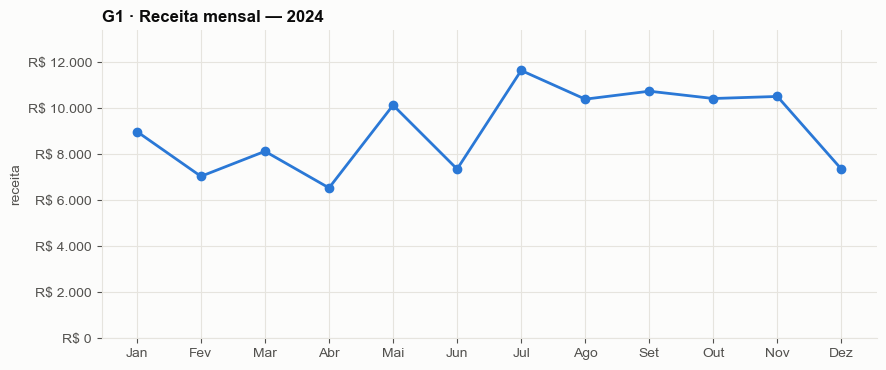

In [29]:
# =====================================================================
# GRÁFICO G1 — Receita mensal
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura e a área do gráfico
ax.plot(t1["nome"], t1["receita"], color=AZUL,            # desenha a linha da receita
        linewidth=2, marker="o", markersize=6)            # linha fina com marcadores nos meses
ax.set_ylim(0, t1["receita"].max() * 1.15)                # eixo começa em zero para não exagerar a variação
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.set_title("G1 · Receita mensal — 2024")                # título identificando o gráfico
ax.set_ylabel("receita")                                  # rótulo do eixo vertical
salvar(fig, "G01_receita_mensal")                         # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 1**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p2"></a>
### Pergunta 2 — Sazonalidade por mês

**Pergunta:** quais meses concentram mais vendas, acima da média do ano?

**Como ler:** barras em azul-escuro estão acima da média anual; em azul-claro, abaixo. A linha tracejada é a média.

**Visual:** barras com linha de referência da média.

In [33]:
# =====================================================================
# TABELA T2 — Meses acima e abaixo da média
# =====================================================================
t2 = t1[["nome", "receita", "desvio_vs_media"]].copy()    # reaproveita a tabela T1
t2["acima_da_media"] = t2["receita"] > MEDIA_MENSAL       # True quando o mês supera a média do ano
MESES_ACIMA = int(t2["acima_da_media"].sum())             # quantos meses ficaram acima

print(f"Meses acima da média: {MESES_ACIMA} de 12")       # resumo
mostrar(t2.sort_values("receita", ascending=False),       # ordena do mês mais forte para o mais fraco
        {"receita": brl, "desvio_vs_media": pct})  # formato de cada coluna

Meses acima da média: 6 de 12


nome,receita,desvio_vs_media,acima_da_media
Jul,"R$ 11.652,93","27,9%",True
Set,"R$ 10.750,49","18,0%",True
Nov,"R$ 10.521,63","15,5%",True
Out,"R$ 10.432,27","14,5%",True
Ago,"R$ 10.403,65","14,2%",True
Mai,"R$ 10.142,67","11,3%",True
Jan,"R$ 8.995,65","-1,3%",False
Mar,"R$ 8.135,14","-10,7%",False
Jun,"R$ 7.362,53","-19,2%",False
Dez,"R$ 7.358,37","-19,2%",False


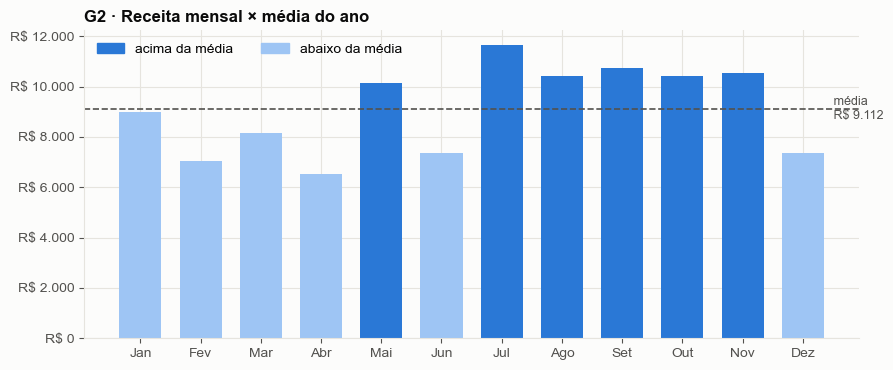

In [35]:
# =====================================================================
# GRÁFICO G2 — Receita mensal × média do ano
# =====================================================================
cores = [AZUL if acima else AZUL_CLARO for acima in t2["acima_da_media"]]  # cor indica acima/abaixo
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.bar(t2["nome"], t2["receita"], color=cores, width=0.7) # barras dos meses
ax.axhline(MEDIA_MENSAL, color=TEXTO_2, linestyle="--", linewidth=1.2)   # linha da média anual
ax.text(11.45, MEDIA_MENSAL, f" média\n {brl(MEDIA_MENSAL, 0)}",          # rótulo direto da média
        va="center", fontsize=9, color=TEXTO_2)  # centralizado, texto secundário
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.set_title("G2 · Receita mensal × média do ano")        # título
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL),          # legenda manual das duas cores
                   plt.Rectangle((0, 0), 1, 1, color=AZUL_CLARO)],  # amostra da cor "abaixo"
          labels=["acima da média", "abaixo da média"], loc="upper left", ncol=2)  # textos e posição da legenda
salvar(fig, "G02_sazonalidade")                           # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 2**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p3"></a>
### Pergunta 3 — Ticket médio ao longo do tempo

**Pergunta:** o cliente está gastando mais ou menos por compra?

**Como ler:** ticket médio = receita do mês ÷ número de vendas do mês. Separa crescimento por mais vendas de crescimento por vendas maiores.

**Visual:** linha com marcadores e referência do ticket do ano.

In [39]:
# =====================================================================
# TABELA T3 — Ticket médio por mês
# =====================================================================
TICKET_ANO = FATURAMENTO / len(df)                        # ticket médio do ano inteiro
t3 = t1[["nome", "vendas", "ticket_medio"]].copy()        # reaproveita a tabela T1
t3["vs_ticket_ano"] = t3["ticket_medio"] / TICKET_ANO - 1 # diferença em relação ao ticket do ano

print(f"Ticket médio do ano: {brl(TICKET_ANO)}")           # resumo
mostrar(t3, {"vendas": num, "ticket_medio": brl, "vs_ticket_ano": pct})  # exibe a tabela

Ticket médio do ano: R$ 109,34


nome,vendas,ticket_medio,vs_ticket_ano
Jan,96,"R$ 93,70","-14,3%"
Fev,71,"R$ 99,24","-9,2%"
Mar,100,"R$ 81,35","-25,6%"
Abr,67,"R$ 97,65","-10,7%"
Mai,91,"R$ 111,46","1,9%"
Jun,75,"R$ 98,17","-10,2%"
Jul,84,"R$ 138,73","26,9%"
Ago,97,"R$ 107,25","-1,9%"
Set,83,"R$ 129,52","18,5%"
Out,71,"R$ 146,93","34,4%"


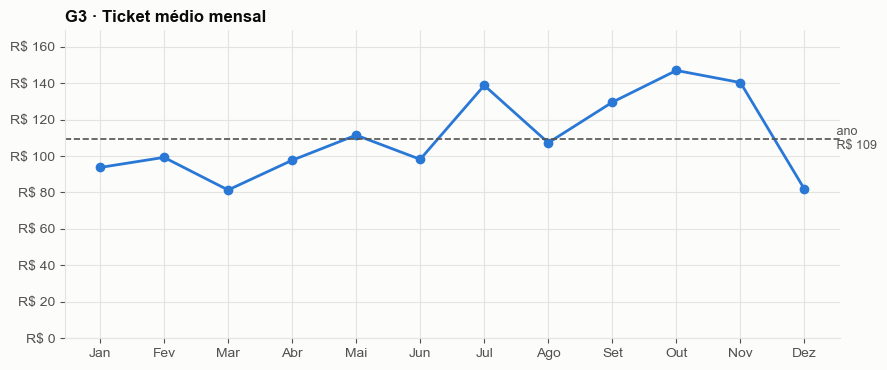

In [41]:
# =====================================================================
# GRÁFICO G3 — Ticket médio mensal
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.plot(t3["nome"], t3["ticket_medio"], color=AZUL,       # linha do ticket médio
        linewidth=2, marker="o", markersize=6)  # linha fina com marcadores
ax.axhline(TICKET_ANO, color=TEXTO_2, linestyle="--", linewidth=1.2)    # referência: ticket do ano
ax.text(11.45, TICKET_ANO, f" ano\n {brl(TICKET_ANO, 0)}", va="center", fontsize=9, color=TEXTO_2)  # rótulo
ax.set_ylim(0, t3["ticket_medio"].max() * 1.15)           # eixo começa em zero
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.set_title("G3 · Ticket médio mensal")                  # título
salvar(fig, "G03_ticket_medio")                           # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 3**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p4"></a>
### Pergunta 4 — Concentração de receita (Pareto)

**Pergunta:** quantas transações respondem por 80% da receita?

**Como ler:** as vendas são ordenadas da maior para a menor e a receita é acumulada. Quanto menor o percentual de vendas que forma 80% da receita, mais concentrada ela é.

**Visual:** curva acumulada com linhas de referência em 80%.

In [45]:
# =====================================================================
# TABELA T4 — Curva de Pareto e indicadores de concentração
# =====================================================================
pareto = (df["valor_total"]                               # pega o valor de cada venda
            .sort_values(ascending=False)                 # ordena da maior para a menor
            .reset_index(drop=True)                       # numera as posições de 0 a 999
            .to_frame("valor"))                           # transforma em tabela
pareto["receita_acumulada"] = pareto["valor"].cumsum() / FATURAMENTO     # % acumulado da receita
pareto["vendas_acumuladas"] = (pareto.index + 1) / len(pareto)          # % acumulado das vendas

VENDAS_80 = int((pareto["receita_acumulada"] < 0.8).sum()) + 1          # vendas até alcançar 80%
TOP10_PCT = pareto.loc[len(pareto) // 10 - 1, "receita_acumulada"]      # receita das 10% maiores vendas

t4 = pd.DataFrame({                                       # tabela-resumo dos indicadores
    "indicador": ["Vendas para formar 80% da receita", "% do total de vendas",  # nomes dos indicadores...
                  "Maior venda", "Receita das 10% maiores vendas"],  # ...continuação dos nomes
    "valor": [num(VENDAS_80), pct(VENDAS_80 / len(df)), brl(pareto["valor"].max()), pct(TOP10_PCT)],  # valores já formatados
})  # fim do bloco
mostrar(t4, {})                                           # exibe sem formatação extra (já é texto)

indicador,valor
Vendas para formar 80% da receita,304
% do total de vendas,"30,4%"
Maior venda,"R$ 1.462,48"
Receita das 10% maiores vendas,"47,3%"


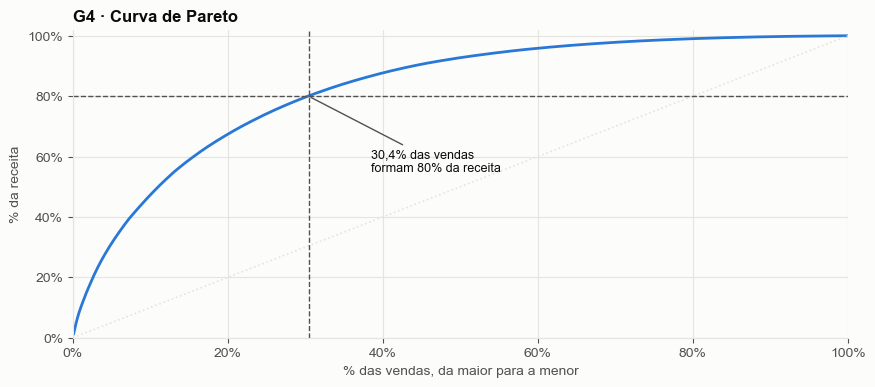

In [47]:
# =====================================================================
# GRÁFICO G4 — Curva de Pareto
# =====================================================================
x80 = VENDAS_80 / len(df)                                 # posição horizontal do ponto de 80%
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.plot(pareto["vendas_acumuladas"], pareto["receita_acumulada"], color=AZUL, linewidth=2)  # curva
ax.plot([0, 1], [0, 1], color=GRADE, linestyle=":", linewidth=1.2)      # diagonal = sem concentração
ax.axhline(0.8, color=TEXTO_2, linestyle="--", linewidth=1)             # referência de 80% da receita
ax.axvline(x80, color=TEXTO_2, linestyle="--", linewidth=1)             # vendas que formam esses 80%
ax.annotate(f"{pct(x80)} das vendas\nformam 80% da receita",            # rótulo direto do ponto-chave
            xy=(x80, 0.8), xytext=(x80 + 0.08, 0.55), fontsize=9, color=TEXTO,  # ponto apontado e posição do texto
            arrowprops={"arrowstyle": "-", "color": TEXTO_2})  # traço ligando texto e ponto
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)                   # eixos de 0% a 100%
ax.xaxis.set_major_formatter(EIXO_PCT)                    # eixo horizontal em percentual
ax.yaxis.set_major_formatter(EIXO_PCT)                    # eixo vertical em percentual
ax.set_xlabel("% das vendas, da maior para a menor")      # rótulo do eixo horizontal
ax.set_ylabel("% da receita")                             # rótulo do eixo vertical
ax.set_title("G4 · Curva de Pareto")                      # título
salvar(fig, "G04_pareto")                                 # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 4**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
## Bloco 2 — Mix de Categorias

<a id="p5"></a>
### Pergunta 5 — Ranking de categorias por receita

**Pergunta:** quais categorias sustentam o faturamento?

**Como ler:** receita e participação de cada categoria, da maior para a menor.

**Visual:** barras horizontais ordenadas.

In [52]:
# =====================================================================
# TABELA T5 — Receita por categoria
# =====================================================================
t5 = (df.groupby("categoria")                             # agrupa por categoria
        .agg(receita=("valor_total", "sum"), vendas=("id_venda", "count"))  # soma e conta
        .reindex(ORDEM_CATEGORIAS)                        # mantém a ordem fixa (maior receita primeiro)
        .reset_index())                                   # categoria vira coluna
t5["participacao"] = t5["receita"] / FATURAMENTO          # % do faturamento
t5["posicao"] = range(1, len(t5) + 1)                     # posição no ranking

mostrar(t5, {"receita": brl, "vendas": num, "participacao": pct})   # exibe a tabela

categoria,receita,vendas,participacao,posicao
Mercearia,"R$ 30.008,46",203,"27,4%",1
Bebidas,"R$ 26.172,15",225,"23,9%",2
Limpeza,"R$ 17.880,79",162,"16,4%",3
Frios,"R$ 12.390,32",102,"11,3%",4
Higiene,"R$ 8.898,98",75,"8,1%",5
Padaria,"R$ 7.820,41",121,"7,2%",6
Hortifruti,"R$ 6.173,26",112,"5,6%",7


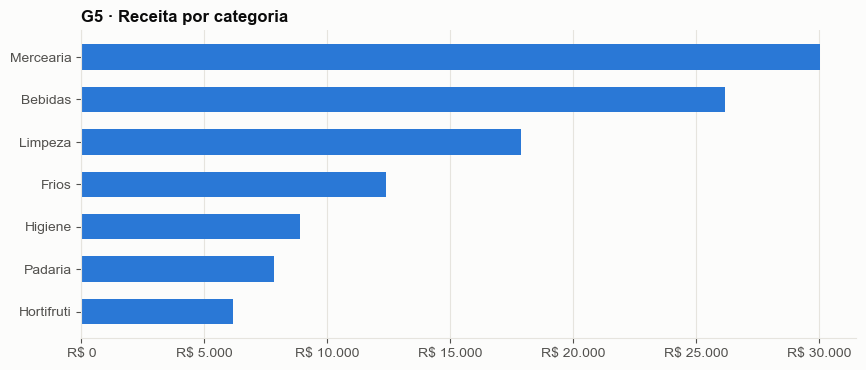

In [54]:
# =====================================================================
# GRÁFICO G5 — Receita por categoria
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.barh(t5["categoria"], t5["receita"], color=AZUL, height=0.6)     # barras horizontais, um só tom
ax.invert_yaxis()                                         # maior receita no topo
ax.xaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.grid(axis="y", visible=False)                          # remove a grade horizontal (desnecessária aqui)
ax.set_title("G5 · Receita por categoria")                # título
salvar(fig, "G05_receita_categoria")                      # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 5**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p6"></a>
### Pergunta 6 — Receita versus volume por categoria

**Pergunta:** quais categorias vendem muito em unidades mas pouco em dinheiro — e vice-versa?

**Como ler:** categoria com % de unidades maior que % de receita é de **tráfego** (atrai movimento); o contrário é de **valor** (sustenta o caixa).

**Visual:** dispersão com o nome de cada categoria no ponto.

In [58]:
# =====================================================================
# TABELA T6 — Unidades × receita por categoria
# =====================================================================
t6 = (df.groupby("categoria")                             # agrupa por categoria
        .agg(unidades=("quantidade", "sum"), receita=("valor_total", "sum"))  # soma unidades e receita
        .reindex(ORDEM_CATEGORIAS).reset_index())         # ordem fixa
t6["pct_unidades"] = t6["unidades"] / df["quantidade"].sum()    # participação em unidades
t6["pct_receita"] = t6["receita"] / FATURAMENTO                 # participação em receita
t6["receita_por_unidade"] = t6["receita"] / t6["unidades"]      # quanto rende cada unidade
t6["perfil"] = np.where(t6["pct_unidades"] > t6["pct_receita"], "tráfego", "valor")  # classificação

mostrar(t6, {"unidades": num, "receita": brl, "pct_unidades": pct, "pct_receita": pct,  # exibe a tabela com formatos...
             "receita_por_unidade": brl})                 # exibe a tabela

categoria,unidades,receita,pct_unidades,pct_receita,receita_por_unidade,perfil
Mercearia,557,"R$ 30.008,46","21,0%","27,4%","R$ 53,88",valor
Bebidas,589,"R$ 26.172,15","22,2%","23,9%","R$ 44,43",valor
Limpeza,430,"R$ 17.880,79","16,2%","16,4%","R$ 41,58",valor
Frios,268,"R$ 12.390,32","10,1%","11,3%","R$ 46,23",valor
Higiene,202,"R$ 8.898,98","7,6%","8,1%","R$ 44,05",valor
Padaria,313,"R$ 7.820,41","11,8%","7,2%","R$ 24,99",tráfego
Hortifruti,290,"R$ 6.173,26","10,9%","5,6%","R$ 21,29",tráfego


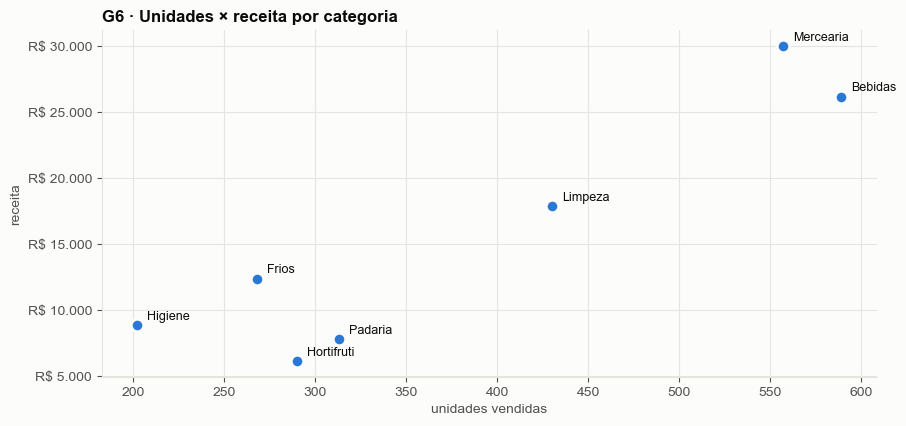

In [60]:
# =====================================================================
# GRÁFICO G6 — Unidades × receita
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4.5))                 # cria a figura
ax.scatter(t6["unidades"], t6["receita"], s=80, color=AZUL,   # um ponto por categoria
           edgecolor=FUNDO, linewidth=2, zorder=3)            # anel claro em volta do ponto
for _, linha in t6.iterrows():                            # percorre as categorias...
    ax.annotate(linha["categoria"], (linha["unidades"], linha["receita"]),  # ...e escreve o nome
                xytext=(7, 4), textcoords="offset points", fontsize=9, color=TEXTO)  # nome um pouco ao lado do ponto
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo vertical em reais
ax.xaxis.set_major_formatter(EIXO_NUM)                    # eixo horizontal em unidades
ax.set_xlabel("unidades vendidas"); ax.set_ylabel("receita")  # rótulos dos eixos
ax.set_title("G6 · Unidades × receita por categoria")     # título
salvar(fig, "G06_unidades_receita")                       # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 6**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p7"></a>
### Pergunta 7 — Dispersão de preço unitário por categoria

**Pergunta:** qual o posicionamento e a variação de preço de cada categoria?

**Como ler:** a caixa vai do 1º ao 3º quartil; a linha no meio é a mediana; os bigodes mostram a faixa típica e os pontos isolados são preços atípicos.

**Visual:** caixa (boxplot) — no Python ele é nativo, sem a adaptação que o Excel exige.

**Filtro aplicado:** só preços observados: as 260 vendas com preço imputado ficam de fora.

In [64]:
# =====================================================================
# TABELA T7 — Cinco números do preço por categoria (sem imputados)
# =====================================================================
precos = df[df["preco_origem"] != PRECO_IMPUTADO]        # remove as 260 vendas com preço estimado
t7 = (precos.groupby("categoria")["preco_unit"]          # agrupa os preços por categoria
        .agg(precos_usados="count", minimo="min",        # quantidade e mínimo
             q1=lambda s: s.quantile(0.25),              # 1º quartil
             mediana="median",                           # mediana
             q3=lambda s: s.quantile(0.75),              # 3º quartil
             maximo="max", media="mean")                 # máximo e média
        .reindex(ORDEM_CATEGORIAS).reset_index())        # ordem fixa

print(f"Preços usados: {len(precos)} de {len(df)} (imputados excluídos: {len(df) - len(precos)})")  # conferência
mostrar(t7, {c: brl for c in ["minimo", "q1", "mediana", "q3", "maximo", "media"]} | {"precos_usados": num})  # exibe: preços em R$, contagem inteira

Preços usados: 740 de 1000 (imputados excluídos: 260)


categoria,precos_usados,minimo,q1,mediana,q3,maximo,media
Mercearia,139,"R$ 3,00","R$ 5,05","R$ 29,18","R$ 78,19","R$ 239,17","R$ 55,71"
Bebidas,170,"R$ 2,50","R$ 5,49","R$ 30,44","R$ 77,09","R$ 177,16","R$ 49,81"
Limpeza,127,"R$ 4,00","R$ 5,53","R$ 21,67","R$ 73,63","R$ 158,10","R$ 44,30"
Frios,76,"R$ 6,00","R$ 9,92","R$ 28,20","R$ 86,30","R$ 207,34","R$ 54,94"
Higiene,54,"R$ 3,50","R$ 6,57","R$ 26,69","R$ 73,22","R$ 145,03","R$ 43,01"
Padaria,87,"R$ 1,50","R$ 3,74","R$ 18,33","R$ 38,45","R$ 87,89","R$ 25,56"
Hortifruti,87,"R$ 1,90","R$ 3,76","R$ 11,31","R$ 30,03","R$ 68,77","R$ 20,03"


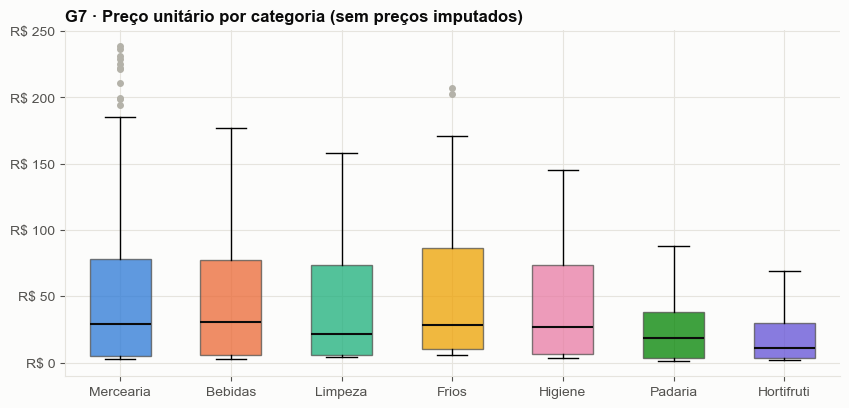

In [66]:
# =====================================================================
# GRÁFICO G7 — Boxplot de preço por categoria
# =====================================================================
dados_box = [precos.loc[precos["categoria"] == c, "preco_unit"] for c in ORDEM_CATEGORIAS]  # uma lista por categoria
fig, ax = plt.subplots(figsize=(10, 4.5))                 # cria a figura
caixas = ax.boxplot(dados_box, patch_artist=True,         # desenha as caixas (preenchíveis)
                    widths=0.55, medianprops={"color": TEXTO, "linewidth": 1.5},   # mediana em preto
                    flierprops={"marker": "o", "markersize": 4, "markerfacecolor": CINZA,  # pontos atípicos pequenos...
                                "markeredgecolor": CINZA})                         # atípicos em cinza
for caixa, cat in zip(caixas["boxes"], ORDEM_CATEGORIAS): # pinta cada caixa com a cor da categoria
    caixa.set_facecolor(COR_CATEGORIA[cat]); caixa.set_alpha(0.75); caixa.set_edgecolor(TEXTO_2)  # cor, transparência e borda
ax.set_xticks(range(1, len(ORDEM_CATEGORIAS) + 1), ORDEM_CATEGORIAS)  # nomes das categorias no eixo
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.set_title("G7 · Preço unitário por categoria (sem preços imputados)")  # título
salvar(fig, "G07_boxplot_preco")                          # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 7**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p8"></a>
### Pergunta 8 — Evolução da participação das categorias

**Pergunta:** alguma categoria está ganhando ou perdendo espaço ao longo do ano?

**Como ler:** cada coluna é a participação da categoria na receita do mês (cada linha soma 100%). No gráfico, uma faixa que engorda está ganhando espaço.

**Visual:** área empilhada 100%, com cores fixas por categoria.

In [70]:
# =====================================================================
# TABELA T8 — Participação mensal de cada categoria
# =====================================================================
t8 = (df.pivot_table(index="mes", columns="categoria",    # matriz mês × categoria...
                     values="valor_total", aggfunc="sum", fill_value=0)  # ...com a receita somada
        [ORDEM_CATEGORIAS])                               # colunas na ordem fixa
t8 = t8.div(t8.sum(axis=1), axis=0)                       # divide pela receita do mês: cada linha soma 100%
t8.index = MESES                                          # troca o número do mês pelo nome

mostrar(t8.reset_index(names="mês"), {c: pct for c in ORDEM_CATEGORIAS})  # exibe a tabela

mês,Mercearia,Bebidas,Limpeza,Frios,Higiene,Padaria,Hortifruti
Jan,"14,1%","34,7%","6,7%","10,2%","9,5%","7,1%","17,7%"
Fev,"39,5%","10,9%","12,9%","22,0%","6,1%","5,5%","3,0%"
Mar,"18,2%","34,5%","10,2%","8,4%","14,2%","10,0%","4,4%"
Abr,"32,3%","17,6%","22,4%","5,2%","9,0%","3,4%","10,1%"
Mai,"6,3%","32,6%","16,4%","21,0%","13,5%","5,6%","4,7%"
Jun,"26,0%","22,9%","24,7%","6,7%","3,5%","10,2%","6,0%"
Jul,"29,7%","20,0%","27,1%","12,5%","4,6%","5,4%","0,6%"
Ago,"47,8%","8,7%","9,5%","14,6%","4,7%","9,4%","5,2%"
Set,"29,1%","22,1%","14,3%","11,8%","16,9%","4,2%","1,5%"
Out,"29,4%","33,0%","10,6%","4,9%","7,0%","9,1%","6,1%"


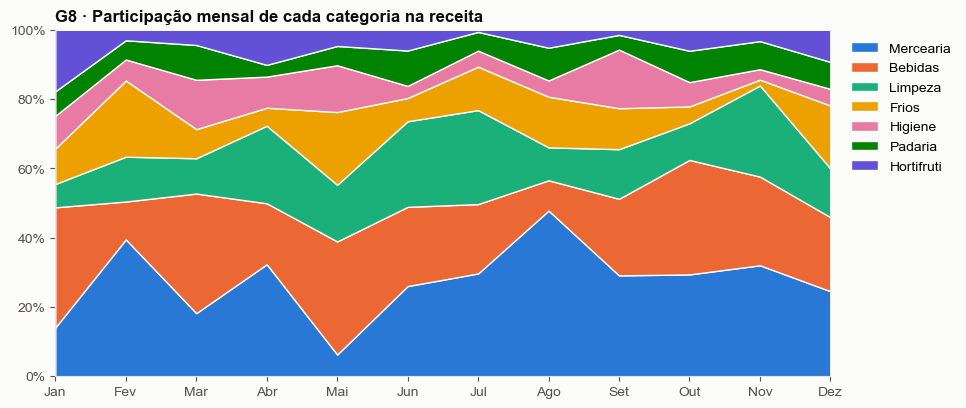

In [72]:
# =====================================================================
# GRÁFICO G8 — Área empilhada 100%
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4.5))                 # cria a figura
ax.stackplot(range(12), [t8[c] for c in ORDEM_CATEGORIAS],          # empilha as categorias
             colors=[COR_CATEGORIA[c] for c in ORDEM_CATEGORIAS],   # cor fixa de cada categoria
             labels=ORDEM_CATEGORIAS, edgecolor=FUNDO, linewidth=1) # fina separação entre faixas
ax.set_xticks(range(12), MESES)                           # nomes dos meses no eixo
ax.set_xlim(0, 11); ax.set_ylim(0, 1)                     # sem margens: a área ocupa todo o quadro
ax.yaxis.set_major_formatter(EIXO_PCT)                    # eixo em percentual
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))     # legenda à direita (7 séries)
ax.set_title("G8 · Participação mensal de cada categoria na receita")  # título
salvar(fig, "G08_participacao_categorias")                # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 8**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
## Bloco 3 — Canais de Venda

"Não informado" reúne as vendas sem canal registrado e aparece sempre em cinza.

<a id="p9"></a>
### Pergunta 9 — Participação de receita por canal

**Pergunta:** quanto cada canal (Loja, Site, App, Televendas) representa?

**Como ler:** '% do total' inclui as vendas sem canal; '% com canal' as exclui. Cite qual está usando.

**Visual:** barras horizontais (mais precisas que pizza para comparar partes).

In [77]:
# =====================================================================
# TABELA T9 — Receita por canal
# =====================================================================
t9 = (df.groupby("canal")                                 # agrupa por canal
        .agg(receita=("valor_total", "sum"), vendas=("id_venda", "count"))  # soma e conta
        .reindex(ORDEM_CANAIS).reset_index())             # ordem fixa, "Não informado" por último
COM_CANAL = t9.loc[t9["canal"] != SEM_CANAL, "receita"].sum()     # receita das vendas com canal
t9["pct_total"] = t9["receita"] / FATURAMENTO                     # % sobre o faturamento total
t9["pct_com_canal"] = np.where(t9["canal"] == SEM_CANAL, np.nan,  # % só entre vendas com canal
                               t9["receita"] / COM_CANAL)  # divide pela receita com canal

mostrar(t9, {"receita": brl, "vendas": num, "pct_total": pct,  # exibe a tabela com formatos...
             "pct_com_canal": lambda v: "—" if pd.isna(v) else pct(v)})   # "—" na linha sem canal

canal,receita,vendas,pct_total,pct_com_canal
Loja,"R$ 38.289,29",339,"35,0%","47,1%"
Site,"R$ 23.622,95",210,"21,6%","29,1%"
App,"R$ 16.769,02",180,"15,3%","20,6%"
Televendas,"R$ 2.567,09",38,"2,3%","3,2%"
Não informado,"R$ 28.096,02",233,"25,7%",—


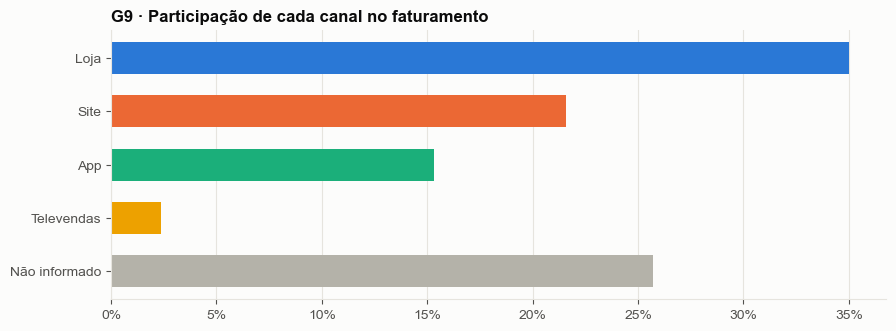

In [79]:
# =====================================================================
# GRÁFICO G9 — Participação por canal
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 3.5))                 # cria a figura
ax.barh(t9["canal"], t9["pct_total"], height=0.6,         # barras com % do total
        color=[COR_CANAL[c] for c in t9["canal"]])        # cor fixa de cada canal
ax.invert_yaxis()                                         # maior no topo
ax.xaxis.set_major_formatter(EIXO_PCT)                    # eixo em percentual
ax.grid(axis="y", visible=False)                          # sem grade horizontal
ax.set_title("G9 · Participação de cada canal no faturamento")  # título
salvar(fig, "G09_participacao_canal")                     # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 9**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p10"></a>
### Pergunta 10 — Ticket médio por canal

**Pergunta:** em qual canal o cliente gasta mais por compra?

**Como ler:** receita do canal ÷ número de vendas do canal; a linha tracejada é o ticket médio do ano.

**Visual:** barras horizontais com referência.

In [83]:
# =====================================================================
# TABELA T10 — Ticket médio por canal
# =====================================================================
t10 = t9[["canal", "receita", "vendas"]].copy()           # reaproveita a tabela T9
t10["ticket_medio"] = t10["receita"] / t10["vendas"]      # ticket médio do canal
t10["vs_ticket_ano"] = t10["ticket_medio"] / TICKET_ANO - 1     # diferença para o ticket do ano

mostrar(t10, {"receita": brl, "vendas": num, "ticket_medio": brl, "vs_ticket_ano": pct})  # exibe

canal,receita,vendas,ticket_medio,vs_ticket_ano
Loja,"R$ 38.289,29",339,"R$ 112,95","3,3%"
Site,"R$ 23.622,95",210,"R$ 112,49","2,9%"
App,"R$ 16.769,02",180,"R$ 93,16","-14,8%"
Televendas,"R$ 2.567,09",38,"R$ 67,55","-38,2%"
Não informado,"R$ 28.096,02",233,"R$ 120,58","10,3%"


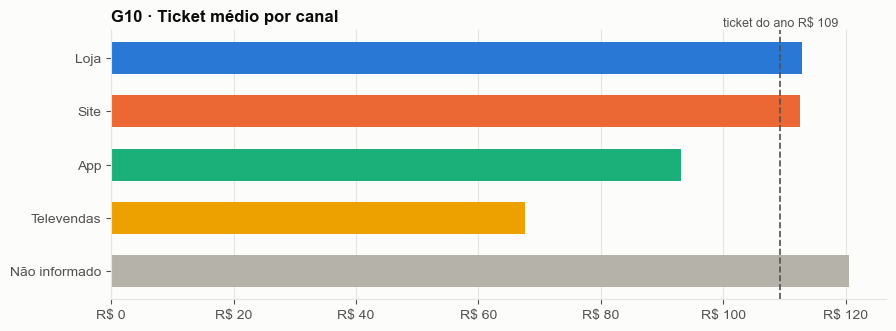

In [85]:
# =====================================================================
# GRÁFICO G10 — Ticket médio por canal
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 3.5))                 # cria a figura
ax.barh(t10["canal"], t10["ticket_medio"], height=0.6,    # barras do ticket médio
        color=[COR_CANAL[c] for c in t10["canal"]])       # cor fixa de cada canal
ax.axvline(TICKET_ANO, color=TEXTO_2, linestyle="--", linewidth=1.2)   # referência: ticket do ano
ax.text(TICKET_ANO, -0.6, f"ticket do ano {brl(TICKET_ANO, 0)}", fontsize=9, color=TEXTO_2, ha="center")  # rótulo
ax.invert_yaxis()                                         # primeiro canal no topo
ax.xaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.grid(axis="y", visible=False)                          # sem grade horizontal
ax.set_title("G10 · Ticket médio por canal")              # título
salvar(fig, "G10_ticket_canal")                           # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 10**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p11"></a>
### Pergunta 11 — Mix de categorias dentro de cada canal

**Pergunta:** o comportamento de compra muda conforme o canal?

**Como ler:** participação de cada categoria na receita do canal (cada linha soma 100%). Tons mais escuros = categoria mais relevante naquele canal.

**Visual:** mapa de calor em um só tom (azul).

In [89]:
# =====================================================================
# TABELA T11 — Categoria dentro de cada canal (% da receita do canal)
# =====================================================================
t11 = (df.pivot_table(index="canal", columns="categoria", # matriz canal × categoria
                      values="valor_total", aggfunc="sum", fill_value=0)  # soma o valor; vazio vira 0
         .reindex(index=ORDEM_CANAIS, columns=ORDEM_CATEGORIAS))   # ordens fixas
t11 = t11.div(t11.sum(axis=1), axis=0)                    # cada linha soma 100%

mostrar(t11.reset_index(), {c: pct for c in ORDEM_CATEGORIAS})     # exibe a tabela

canal,Mercearia,Bebidas,Limpeza,Frios,Higiene,Padaria,Hortifruti
Loja,"29,2%","22,4%","19,1%","12,9%","5,8%","4,5%","6,0%"
Site,"24,1%","20,4%","16,6%","15,0%","7,9%","9,7%","6,3%"
App,"27,9%","25,7%","15,2%","8,2%","8,0%","6,6%","8,5%"
Televendas,"62,0%","15,8%","2,5%","1,9%","3,1%","8,5%","6,2%"
Não informado,"24,4%","28,6%","14,4%","8,9%","12,0%","8,8%","2,9%"


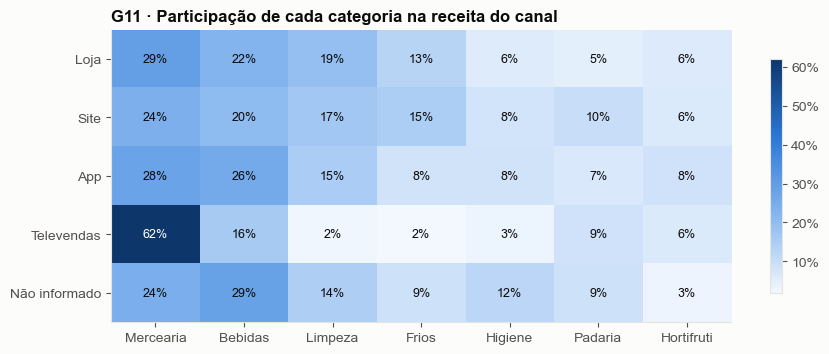

In [91]:
# =====================================================================
# GRÁFICO G11 — Mapa de calor canal × categoria
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 3.8))                 # cria a figura
imagem = ax.imshow(t11.values, cmap=RAMPA_AZUL, aspect="auto")     # pinta cada célula pela participação
ax.set_xticks(range(len(ORDEM_CATEGORIAS)), ORDEM_CATEGORIAS)      # categorias no eixo horizontal
ax.set_yticks(range(len(ORDEM_CANAIS)), ORDEM_CANAIS)              # canais no eixo vertical
ax.grid(False)                                            # mapa de calor não leva grade
limite = t11.values.max() * 0.6                           # acima disso, o texto fica branco
for i in range(t11.shape[0]):                             # escreve o valor em cada célula...
    for j in range(t11.shape[1]):  # ...percorrendo cada coluna
        v = t11.values[i, j]  # valor da célula
        ax.text(j, i, pct(v, 0), ha="center", va="center", fontsize=9,  # escreve o percentual no centro...
                color="white" if v > limite else TEXTO)   # ...com cor legível sobre o fundo
ax.set_title("G11 · Participação de cada categoria na receita do canal")  # título
fig.colorbar(imagem, ax=ax, format=EIXO_PCT, shrink=0.8)  # barra de escala de cor
salvar(fig, "G11_canal_categoria")                        # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 11**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
## Bloco 4 — Geografia

"NI" reúne as vendas sem UF registrada e aparece sempre em cinza.

<a id="p12"></a>
### Pergunta 12 — Receita por unidade federativa

**Pergunta:** onde está concentrada a operação?

**Como ler:** UFs ordenadas pela receita; 'NI' por último. UFs abaixo da massa mínima têm média instável.

**Visual:** barras horizontais (um mapa coroplético exige arquivo de fronteiras — fica para o dashboard final).

In [96]:
# =====================================================================
# TABELA T12 — Receita por UF
# =====================================================================
t12 = (df.groupby("uf")                                   # agrupa por UF
         .agg(receita=("valor_total", "sum"), vendas=("id_venda", "count"))  # soma e conta
         .sort_values("receita", ascending=False))        # maior receita primeiro
t12 = pd.concat([t12.drop(SEM_UF), t12.loc[[SEM_UF]]]).reset_index()      # "NI" vai para o fim
t12["participacao"] = t12["receita"] / FATURAMENTO        # % do faturamento
t12["massa_suficiente"] = t12["vendas"] >= MASSA_MINIMA_UF    # UF com vendas suficientes para comparar

mostrar(t12, {"receita": brl, "vendas": num, "participacao": pct})   # exibe a tabela

uf,receita,vendas,participacao,massa_suficiente
SP,"R$ 22.877,15",227,"20,9%",True
MG,"R$ 9.957,00",79,"9,1%",True
BA,"R$ 8.549,11",54,"7,8%",True
RJ,"R$ 7.484,96",94,"6,8%",True
CE,"R$ 5.699,85",41,"5,2%",True
RS,"R$ 5.225,46",43,"4,8%",True
PE,"R$ 5.064,29",36,"4,6%",True
ES,"R$ 4.022,49",22,"3,7%",True
PR,"R$ 3.879,87",40,"3,5%",True
GO,"R$ 3.860,62",33,"3,5%",True


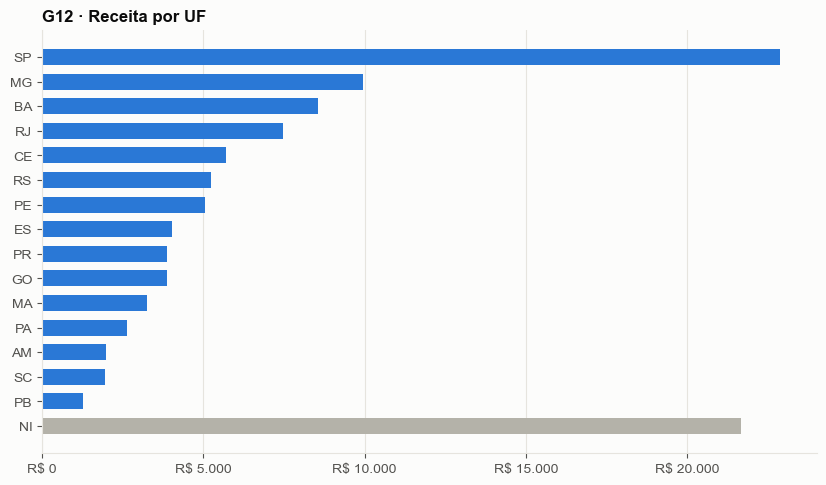

In [98]:
# =====================================================================
# GRÁFICO G12 — Receita por UF
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 5.5))                 # cria a figura
ax.barh(t12["uf"], t12["receita"], height=0.65,           # barras por UF
        color=[CINZA if u == SEM_UF else AZUL for u in t12["uf"]])   # "NI" em cinza
ax.invert_yaxis()                                         # maior receita no topo
ax.xaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.grid(axis="y", visible=False)                          # sem grade horizontal
ax.set_title("G12 · Receita por UF")                      # título
salvar(fig, "G12_receita_uf")                             # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 12**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p13"></a>
### Pergunta 13 — Grau de concentração geográfica

**Pergunta:** qual a dependência das praças principais?

**Como ler:** quanto da receita vem das 3 e das 5 maiores UFs, com dois denominadores: o faturamento total e só a receita com UF informada.

**Visual:** cartões de indicador (número em destaque) — a resposta é um número, não uma comparação.

In [102]:
# =====================================================================
# TABELA T13 — Concentração nas maiores UFs
# =====================================================================
ufs = t12[t12["uf"] != SEM_UF]                            # só UFs informadas, já ordenadas
COM_UF = ufs["receita"].sum()                             # receita com UF informada
linhas = []                                               # acumula as linhas da tabela
for n in (3, 5):                                          # calcula para o top 3 e o top 5
    receita_top = ufs.head(n)["receita"].sum()            # soma das n maiores
    linhas.append({"indicador": f"Top {n} UFs ({', '.join(ufs.head(n)['uf'])})",   # nome com as UFs
                   "receita": receita_top,  # receita somada
                   "pct_total": receita_top / FATURAMENTO,                       # sobre o total
                   "pct_com_uf": receita_top / COM_UF})                          # sobre a receita com UF
t13 = pd.DataFrame(linhas)                                # monta a tabela
TOP3_RECEITA = t13.loc[0, "receita"]                      # guardado para a conferência final

mostrar(t13, {"receita": brl, "pct_total": pct, "pct_com_uf": pct})   # exibe a tabela

indicador,receita,pct_total,pct_com_uf
"Top 3 UFs (SP, MG, BA)","R$ 41.383,26","37,8%","47,2%"
"Top 5 UFs (SP, MG, BA, RJ, CE)","R$ 54.568,07","49,9%","62,2%"


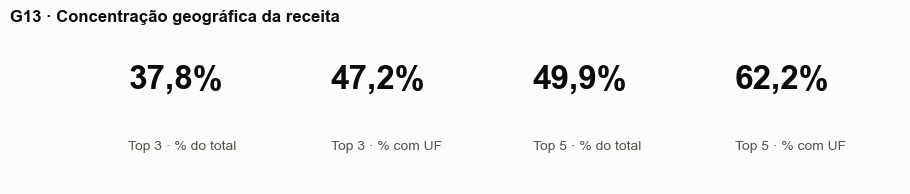

In [104]:
# =====================================================================
# GRÁFICO G13 — Cartões de indicador
# =====================================================================
fig, eixos = plt.subplots(1, 4, figsize=(10, 2))          # quatro cartões lado a lado
cartoes = [("Top 3 · % do total", t13.loc[0, "pct_total"]), ("Top 3 · % com UF", t13.loc[0, "pct_com_uf"]),  # rótulo e valor de cada cartão...
           ("Top 5 · % do total", t13.loc[1, "pct_total"]), ("Top 5 · % com UF", t13.loc[1, "pct_com_uf"])]  # ...cartões do top 5
for ax, (rotulo, valor) in zip(eixos, cartoes):           # desenha cada cartão
    ax.axis("off")                                        # cartão não tem eixos
    ax.text(0.02, 0.62, pct(valor), fontsize=24, fontweight="bold", color=TEXTO)   # número em destaque
    ax.text(0.02, 0.22, rotulo, fontsize=10, color=TEXTO_2)                         # legenda do número
fig.suptitle("G13 · Concentração geográfica da receita", x=0.01, ha="left",        # título do conjunto
             fontsize=12, fontweight="bold", color=TEXTO)  # mesmo estilo dos outros títulos
salvar(fig, "G13_concentracao_uf")                        # grava o PNG, se habilitado
plt.show()                                                # mostra os cartões

> **Sua conclusão — pergunta 13**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p14"></a>
### Pergunta 14 — Canal preferencial por região

**Pergunta:** o canal de compra varia geograficamente?

**Como ler:** participação de cada canal no número de vendas da UF (cada barra soma 100%). Só UFs com a massa mínima de vendas definida em `MASSA_MINIMA_UF`.

**Visual:** barras empilhadas 100%, com cores fixas por canal.

In [108]:
# =====================================================================
# TABELA T14 — Canal dentro de cada UF (% das vendas)
# =====================================================================
ufs_validas = t12.loc[t12["massa_suficiente"] & (t12["uf"] != SEM_UF), "uf"].tolist()  # UFs comparáveis
t14 = (pd.crosstab(df["uf"], df["canal"], normalize="index")    # % de vendas de cada canal na UF
         .reindex(index=ufs_validas, columns=ORDEM_CANAIS)      # só UFs válidas, canais em ordem fixa
         .fillna(0))                                            # canal sem venda na UF = 0%

print(f"UFs com pelo menos {MASSA_MINIMA_UF} vendas: {len(ufs_validas)} de {len(t12) - 1}")  # conferência
mostrar(t14.reset_index(), {c: pct for c in ORDEM_CANAIS})      # exibe a tabela

UFs com pelo menos 15 vendas: 14 de 15


uf,Loja,Site,App,Televendas,Não informado
SP,"33,9%","17,6%","20,3%","5,3%","22,9%"
MG,"40,5%","24,1%","15,2%","1,3%","19,0%"
BA,"37,0%","16,7%","14,8%","3,7%","27,8%"
RJ,"37,2%","21,3%","18,1%","2,1%","21,3%"
CE,"29,3%","19,5%","31,7%","0,0%","19,5%"
RS,"37,2%","16,3%","25,6%","2,3%","18,6%"
PE,"25,0%","25,0%","13,9%","5,6%","30,6%"
ES,"36,4%","31,8%","13,6%","4,5%","13,6%"
PR,"30,0%","10,0%","12,5%","7,5%","40,0%"
GO,"30,3%","24,2%","15,2%","3,0%","27,3%"


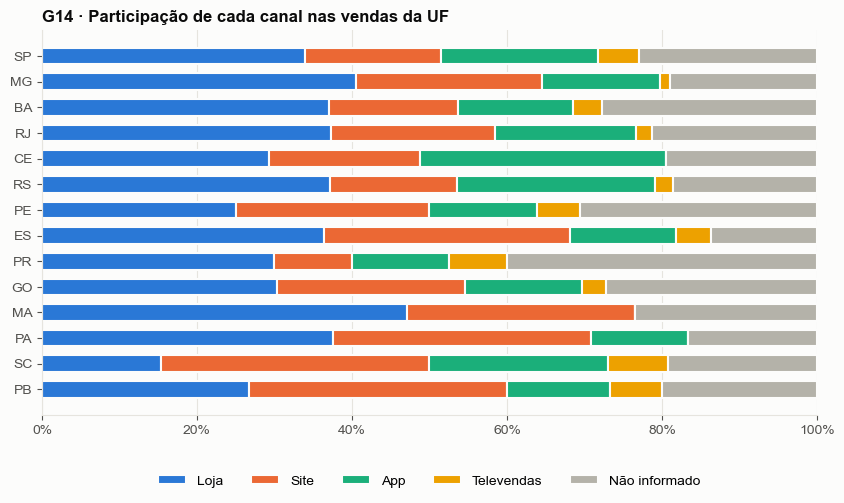

In [110]:
# =====================================================================
# GRÁFICO G14 — Canais por UF
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 5))                   # cria a figura
esquerda = np.zeros(len(t14))                             # início de cada segmento
for canal in ORDEM_CANAIS:                                # empilha um canal de cada vez
    ax.barh(t14.index, t14[canal], left=esquerda, height=0.65, color=COR_CANAL[canal],  # segmento do canal...
            label=canal, edgecolor=FUNDO, linewidth=1.5)  # separação clara entre segmentos
    esquerda += t14[canal].values                         # o próximo segmento começa onde este termina
ax.invert_yaxis()                                         # maior UF no topo
ax.set_xlim(0, 1)                                         # barras de 0% a 100%
ax.xaxis.set_major_formatter(EIXO_PCT)                    # eixo em percentual
ax.grid(axis="y", visible=False)                          # sem grade horizontal
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=len(ORDEM_CANAIS))  # legenda abaixo
ax.set_title("G14 · Participação de cada canal nas vendas da UF")   # título
salvar(fig, "G14_canal_uf")                               # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 14**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
## Bloco 5 — Clientes

<a id="p15"></a>
### Pergunta 15 — Recorrência de compra

**Pergunta:** qual a proporção de clientes recorrentes na base?

**Como ler:** quantos clientes compraram 1 vez, 2 vezes, e assim por diante. Recorrente = 2 compras ou mais.

**Visual:** histograma (barras por número de compras).

In [115]:
# =====================================================================
# TABELA T15 — Clientes por número de compras
# =====================================================================
clientes = (df.groupby("cliente")                         # uma linha por cliente
              .agg(compras=("id_venda", "count"),         # quantas compras fez
                   receita=("valor_total", "sum"),        # quanto gastou
                   ultima_compra=("data", "max")))        # quando comprou pela última vez
t15 = (clientes["compras"].value_counts()                 # quantos clientes para cada nº de compras
         .sort_index().rename_axis("compras")             # ordena de 1 compra em diante
         .reset_index(name="clientes"))  # volta a ser tabela
t15["pct_clientes"] = t15["clientes"] / len(clientes)     # % dos clientes
RECORRENTES = int((clientes["compras"] >= 2).sum())       # clientes com 2 compras ou mais

print(f"Clientes: {len(clientes)} · recorrentes: {RECORRENTES} ({pct(RECORRENTES / len(clientes))}) "  # resumo, 1ª parte...
      f"· compras por cliente: {clientes['compras'].mean():.2f}".replace(".", ","))   # resumo
mostrar(t15, {"clientes": num, "pct_clientes": pct})      # exibe a tabela

Clientes: 245 · recorrentes: 230 (93,9%) · compras por cliente: 4,08


compras,clientes,pct_clientes
1,15,"6,1%"
2,41,"16,7%"
3,48,"19,6%"
4,45,"18,4%"
5,48,"19,6%"
6,18,"7,3%"
7,18,"7,3%"
8,5,"2,0%"
9,5,"2,0%"
10,2,"0,8%"


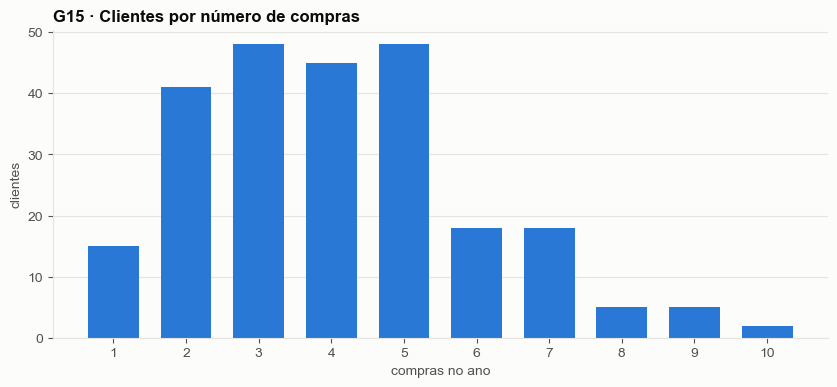

In [117]:
# =====================================================================
# GRÁFICO G15 — Clientes por número de compras
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.bar(t15["compras"], t15["clientes"], color=AZUL, width=0.7)     # uma barra por número de compras
ax.set_xticks(t15["compras"])                             # um rótulo para cada número de compras
ax.set_xlabel("compras no ano"); ax.set_ylabel("clientes")  # rótulos dos eixos
ax.grid(axis="x", visible=False)                          # sem grade vertical
ax.set_title("G15 · Clientes por número de compras")      # título
salvar(fig, "G15_recorrencia")                            # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 15**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p16"></a>
### Pergunta 16 — Top clientes por receita

**Pergunta:** quem são os clientes de maior valor?

**Como ler:** os 20 clientes com maior receita; '% acumulado' mostra quanto eles somam juntos.

**Visual:** barras horizontais ordenadas.

In [121]:
# =====================================================================
# TABELA T16 — Top 20 clientes
# =====================================================================
t16 = (clientes.sort_values("receita", ascending=False)   # ordena do maior para o menor
               .head(20).reset_index())                   # fica com os 20 primeiros
t16.insert(0, "posicao", range(1, 21))                    # coluna de posição no ranking
t16["pct_receita"] = t16["receita"] / FATURAMENTO         # % do faturamento de cada um
t16["pct_acumulado"] = t16["pct_receita"].cumsum()        # % acumulado do top

mostrar(t16[["posicao", "cliente", "receita", "compras", "pct_receita", "pct_acumulado"]],  # colunas exibidas...
        {"receita": brl, "compras": num, "pct_receita": pct, "pct_acumulado": pct})   # exibe a tabela

posicao,cliente,receita,compras,pct_receita,pct_acumulado
1,CLI-0149,"R$ 1.770,31",7,"1,6%","1,6%"
2,CLI-0096,"R$ 1.740,39",8,"1,6%","3,2%"
3,CLI-0250,"R$ 1.718,86",7,"1,6%","4,8%"
4,CLI-0037,"R$ 1.614,56",6,"1,5%","6,3%"
5,CLI-0137,"R$ 1.576,78",6,"1,4%","7,7%"
6,CLI-0042,"R$ 1.570,61",3,"1,4%","9,1%"
7,CLI-0021,"R$ 1.511,70",5,"1,4%","10,5%"
8,CLI-0214,"R$ 1.457,49",2,"1,3%","11,9%"
9,CLI-0004,"R$ 1.371,52",6,"1,3%","13,1%"
10,CLI-0151,"R$ 1.357,39",5,"1,2%","14,3%"


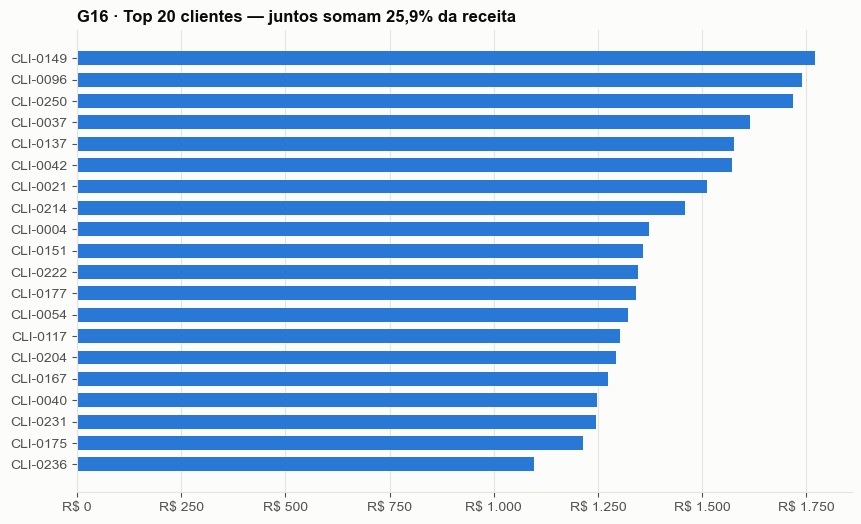

In [123]:
# =====================================================================
# GRÁFICO G16 — Top 20 clientes
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 6))                   # cria a figura
ax.barh(t16["cliente"], t16["receita"], color=AZUL, height=0.65)   # barras por cliente
ax.invert_yaxis()                                         # maior cliente no topo
ax.xaxis.set_major_formatter(EIXO_BRL)                    # eixo em reais
ax.grid(axis="y", visible=False)                          # sem grade horizontal
ax.set_title(f"G16 · Top 20 clientes — juntos somam {pct(t16['pct_acumulado'].iloc[-1])} da receita")  # título
salvar(fig, "G16_top_clientes")                           # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 16**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p17"></a>
### Pergunta 17 — Segmentação RFV (Recência, Frequência, Valor)

**Pergunta:** como classificar a base em grupos acionáveis?

**Como ler:** cada cliente recebe nota de 1 a 4 em Recência, Frequência e Valor, por quartis. A soma (3 a 12) define o segmento pelos limites `RFV_*` da seção 0.2, que você pode mudar.

**Visual:** barras de receita por segmento + dispersão frequência × valor.

In [127]:
# =====================================================================
# TABELA T17 — Notas RFV e segmentos (mesma regra do Excel)
# =====================================================================
DATA_REF = df["data"].max() + pd.DateOffset(days=1)       # dia seguinte à última venda
rfv = clientes.copy()                                     # parte da tabela de clientes
rfv["recencia"] = (DATA_REF - rfv["ultima_compra"]).dt.days   # dias desde a última compra

def nota(serie, menor_e_melhor=False):  # função: nota de 1 a 4 por quartis
    """Nota de 1 a 4 por quartis (mesma lógica do QUARTILE do Excel)."""
    q1, q2, q3 = serie.quantile([0.25, 0.5, 0.75])        # três cortes de quartil
    if menor_e_melhor:                                    # recência: menos dias = nota maior
        return np.select([serie <= q1, serie <= q2, serie <= q3], [4, 3, 2], default=1)  # até Q1=4, até Q2=3, até Q3=2, resto=1
    return np.select([serie > q3, serie > q2, serie > q1], [4, 3, 2], default=1)  # frequência e valor

rfv["R"] = nota(rfv["recencia"], menor_e_melhor=True)     # nota de recência
rfv["F"] = nota(rfv["compras"])                           # nota de frequência
rfv["V"] = nota(rfv["receita"])                           # nota de valor
rfv["RFV"] = rfv["R"] + rfv["F"] + rfv["V"]               # soma das notas (3 a 12)
rfv["segmento"] = np.select([rfv["RFV"] >= RFV_CAMPEOES,  # aplica os limites da seção 0.2
                             rfv["RFV"] >= RFV_LEAIS,  # ...ou Leais
                             rfv["RFV"] >= RFV_ATENCAO],  # ...ou Atenção
                            ["Campeões", "Leais", "Atenção"], default="Em risco")  # nomes; abaixo de tudo = Em risco

SEGMENTOS = ["Campeões", "Leais", "Atenção", "Em risco"]  # ordem de exibição
t17 = (rfv.groupby("segmento")                            # resume por segmento
          .agg(clientes=("RFV", "count"), receita=("receita", "sum"), compras_medias=("compras", "mean"))  # conta, soma e média
          .reindex(SEGMENTOS).reset_index())  # ordem fixa dos segmentos
t17["pct_receita"] = t17["receita"] / FATURAMENTO         # % do faturamento

print(f"Data de referência: {DATA_REF:%d/%m/%Y}")         # conferência
mostrar(t17, {"clientes": num, "receita": brl, "compras_medias": lambda v: num(v, 1), "pct_receita": pct})  # exibe a tabela

Data de referência: 01/01/2025


segmento,clientes,receita,compras_medias,pct_receita
Campeões,49,"R$ 45.269,08","6,6","41,4%"
Leais,94,"R$ 45.075,50","4,3","41,2%"
Atenção,55,"R$ 14.103,79","3,2","12,9%"
Em risco,47,"R$ 4.896,00","2,0","4,5%"


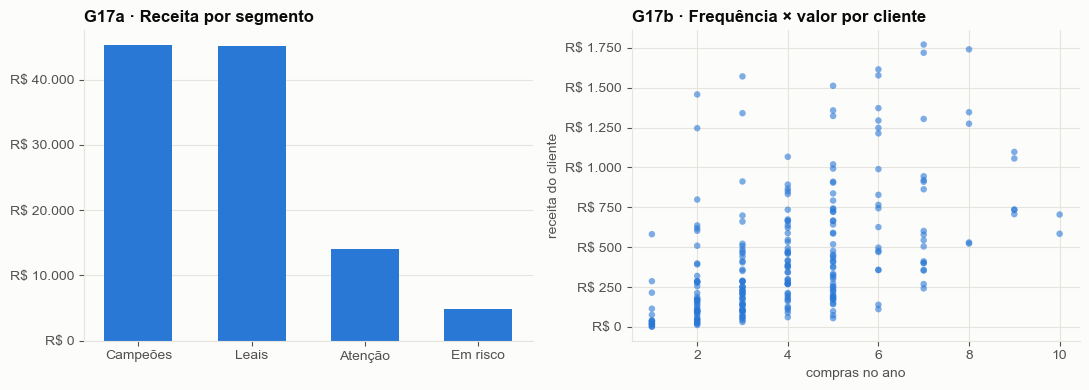

In [129]:
# =====================================================================
# GRÁFICO G17 — Receita por segmento e frequência × valor
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))     # dois gráficos lado a lado
ax1.bar(t17["segmento"], t17["receita"], color=AZUL, width=0.6)    # receita de cada segmento
ax1.yaxis.set_major_formatter(EIXO_BRL)                   # eixo em reais
ax1.grid(axis="x", visible=False)                         # sem grade vertical
ax1.set_title("G17a · Receita por segmento")              # título do primeiro gráfico
ax2.scatter(rfv["compras"], rfv["receita"], s=22, color=AZUL, alpha=0.6, edgecolor="none")  # um ponto por cliente
ax2.yaxis.set_major_formatter(EIXO_BRL)                   # eixo em reais
ax2.set_xlabel("compras no ano"); ax2.set_ylabel("receita do cliente")   # rótulos
ax2.set_title("G17b · Frequência × valor por cliente")    # título do segundo gráfico
fig.tight_layout()                                        # evita sobreposição entre os dois
salvar(fig, "G17_rfv")                                    # grava o PNG, se habilitado
plt.show()                                                # mostra os gráficos

> **Sua conclusão — pergunta 17**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
## Bloco 6 — Preço e Desconto

As três perguntas deste bloco usam apenas descontos **observados ou recalculados** da própria venda:
as 69 vendas com desconto imputado pela mediana ficam de fora.

<a id="p18"></a>
### Pergunta 18 — Distribuição da política de desconto

**Pergunta:** como os descontos estão sendo aplicados na prática?

**Como ler:** quantas vendas caem em cada faixa de desconto.

**Visual:** histograma por faixas (mesmas do Excel).

**Filtro aplicado:** exclui as 69 vendas com desconto imputado.

In [134]:
# =====================================================================
# TABELA T18 — Vendas por faixa de desconto
# =====================================================================
descontos = df[df["desconto_origem"] != DESCONTO_IMPUTADO]   # remove os descontos estimados
cortes = [-0.001, 0, 1, 2, 3, 5, 10, 20]                  # limites das faixas (em pontos percentuais)
rotulos = ["Sem desconto", "até 1%", "1% a 2%", "2% a 3%", "3% a 5%", "5% a 10%", "10% a 20%"]  # nomes
faixa = pd.cut(descontos["desconto_pct"], bins=cortes, labels=rotulos)  # classifica cada venda numa faixa
t18 = faixa.value_counts().reindex(rotulos).rename_axis("faixa").reset_index(name="vendas")  # conta por faixa
t18["pct_vendas"] = t18["vendas"] / len(descontos)        # % das vendas consideradas

print(f"Vendas consideradas: {len(descontos)} · desconto médio: {num(descontos['desconto_pct'].mean(), 2)}% · "  # resumo, 1ª parte...
      f"mediano: {num(descontos['desconto_pct'].median(), 2)}% · maior: {num(descontos['desconto_pct'].max(), 2)}%")  # ...mediana e máximo
mostrar(t18, {"vendas": num, "pct_vendas": pct})          # exibe a tabela

Vendas consideradas: 931 · desconto médio: 2,88% · mediano: 1,89% · maior: 18,00%


faixa,vendas,pct_vendas
Sem desconto,173,"18,6%"
até 1%,145,"15,6%"
1% a 2%,170,"18,3%"
2% a 3%,108,"11,6%"
3% a 5%,166,"17,8%"
5% a 10%,127,"13,6%"
10% a 20%,42,"4,5%"


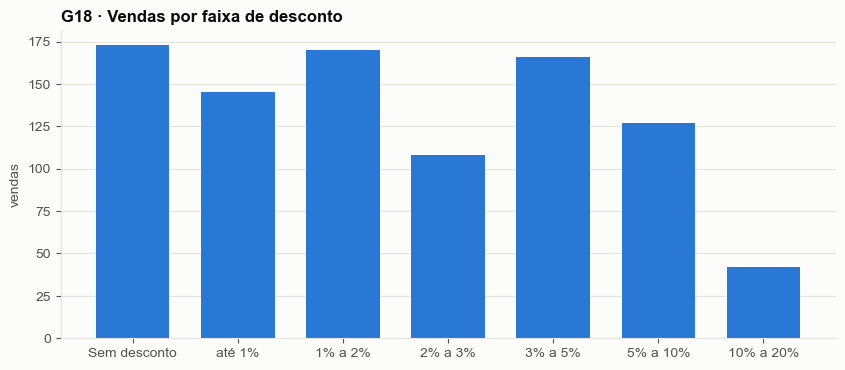

In [136]:
# =====================================================================
# GRÁFICO G18 — Vendas por faixa de desconto
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4))                   # cria a figura
ax.bar(t18["faixa"].astype(str), t18["vendas"], color=AZUL, width=0.7)   # uma barra por faixa
ax.set_ylabel("vendas")                                   # rótulo do eixo vertical
ax.grid(axis="x", visible=False)                          # sem grade vertical
ax.set_title("G18 · Vendas por faixa de desconto")        # título
salvar(fig, "G18_faixas_desconto")                        # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 18**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p19"></a>
### Pergunta 19 — Desconto médio por categoria e canal

**Pergunta:** onde a empresa concede mais desconto?

**Como ler:** desconto médio, em pontos percentuais, de cada combinação. Tons mais escuros = mais desconto.

**Visual:** mapa de calor em um só tom (laranja, para não confundir com o azul do bloco 3).

**Filtro aplicado:** exclui as 69 vendas com desconto imputado.

In [140]:
# =====================================================================
# TABELA T19 — Desconto médio categoria × canal
# =====================================================================
t19 = (descontos.pivot_table(index="categoria", columns="canal",   # matriz categoria × canal
                             values="desconto_pct", aggfunc="mean")  # com o desconto médio
          .reindex(index=ORDEM_CATEGORIAS, columns=ORDEM_CANAIS))  # ordens fixas

mostrar(t19.reset_index(), {c: (lambda v: "—" if pd.isna(v) else f"{num(v, 2)}%") for c in ORDEM_CANAIS})  # "—" onde não há vendas

categoria,Loja,Site,App,Televendas,Não informado
Mercearia,"2,57%","3,36%","3,21%","2,66%","3,32%"
Bebidas,"2,86%","2,58%","2,92%","6,69%","2,72%"
Limpeza,"2,66%","2,88%","3,40%","2,85%","2,82%"
Frios,"4,15%","2,28%","2,50%","0,69%","2,26%"
Higiene,"3,19%","2,49%","4,09%","3,31%","2,80%"
Padaria,"2,59%","3,14%","2,69%","3,27%","2,49%"
Hortifruti,"2,90%","3,41%","2,70%","0,79%","2,23%"


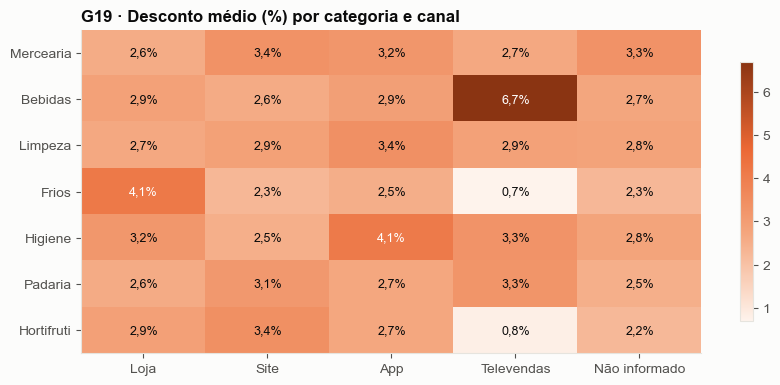

In [142]:
# =====================================================================
# GRÁFICO G19 — Mapa de calor de desconto
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4.2))                 # cria a figura
imagem = ax.imshow(t19.values, cmap=RAMPA_LARANJA, aspect="auto")  # pinta pelo desconto médio
ax.set_xticks(range(len(ORDEM_CANAIS)), ORDEM_CANAIS)     # canais no eixo horizontal
ax.set_yticks(range(len(ORDEM_CATEGORIAS)), ORDEM_CATEGORIAS)      # categorias no eixo vertical
ax.grid(False)                                            # mapa de calor não leva grade
limite = np.nanmax(t19.values) * 0.6                      # acima disso, o texto fica branco
for i in range(t19.shape[0]):                             # escreve o valor em cada célula...
    for j in range(t19.shape[1]):  # ...percorrendo cada coluna
        v = t19.values[i, j]  # valor da célula
        if not np.isnan(v):                               # ...exceto combinações sem vendas
            ax.text(j, i, f"{num(v, 1)}%", ha="center", va="center", fontsize=9,  # escreve o desconto no centro...
                    color="white" if v > limite else TEXTO)  # ...com cor legível sobre o fundo
ax.set_title("G19 · Desconto médio (%) por categoria e canal")     # título
fig.colorbar(imagem, ax=ax, shrink=0.8)                   # barra de escala de cor
salvar(fig, "G19_desconto_categoria_canal")               # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 19**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

<a id="p20"></a>
### Pergunta 20 — Relação entre desconto e valor da venda

**Pergunta:** desconto maior gera venda maior?

**Como ler:** a correlação vai de −1 a +1; perto de zero, não há relação linear. **Correlação não prova causa**: uma relação positiva pode significar que vendas maiores recebem mais desconto (política por volume), e não que o desconto gera a venda.

**Visual:** dispersão com reta de tendência.

**Filtro aplicado:** exclui as 69 vendas com desconto imputado (no Python o filtro vale também para o gráfico).

In [146]:
# =====================================================================
# TABELA T20 — Correlação entre desconto e valor
# =====================================================================
x = descontos["desconto_pct"]                             # desconto de cada venda válida
y = descontos["valor_total"]                              # valor de cada venda válida
CORREL_VALIDAS = x.corr(y)                                # correlação de Pearson, só vendas válidas
CORREL_TODAS = df["desconto_pct"].corr(df["valor_total"]) # mesma conta com todas as vendas
inclinacao, intercepto = np.polyfit(x, y, 1)              # reta de tendência: y = a·x + b

t20 = pd.DataFrame({                                      # tabela-resumo
    "medida": ["Vendas consideradas", "Correlação (descontos válidos)", "Correlação (todas as vendas)",  # nomes das medidas...
               "R² (força da relação linear)", "Reta de tendência"],  # ...continuação dos nomes
    "valor": [num(len(descontos)), num(CORREL_VALIDAS, 3), num(CORREL_TODAS, 3),  # valores formatados...
              num(CORREL_VALIDAS ** 2, 3), f"valor = {num(inclinacao, 2)} × desconto + {num(intercepto, 2)}"],  # ...R² e equação da reta
})  # fim do bloco
mostrar(t20, {})                                          # exibe a tabela

medida,valor
Vendas consideradas,931
Correlação (descontos válidos),"0,407"
Correlação (todas as vendas),"0,392"
R² (força da relação linear),"0,165"
Reta de tendência,"valor = 21,13 × desconto + 48,02"


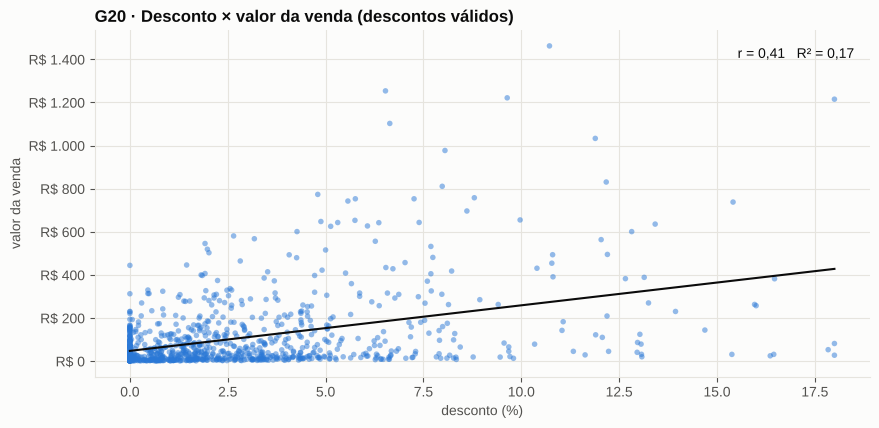

In [44]:
# =====================================================================
# GRÁFICO G20 — Desconto × valor da venda
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 4.5))                 # cria a figura
ax.scatter(x, y, s=16, color=AZUL, alpha=0.5, edgecolor="none")    # uma bolinha por venda
xs = np.linspace(x.min(), x.max(), 50)                    # pontos para desenhar a reta
ax.plot(xs, inclinacao * xs + intercepto, color=TEXTO, linewidth=1.5)   # reta de tendência
ax.text(0.98, 0.92, f"r = {num(CORREL_VALIDAS, 2)}   R² = {num(CORREL_VALIDAS ** 2, 2)}",   # rótulo direto
        transform=ax.transAxes, ha="right", fontsize=10, color=TEXTO)  # posição relativa ao quadro
ax.yaxis.set_major_formatter(EIXO_BRL)                    # eixo vertical em reais
ax.set_xlabel("desconto (%)"); ax.set_ylabel("valor da venda")      # rótulos dos eixos
ax.set_title("G20 · Desconto × valor da venda (descontos válidos)")  # título
salvar(fig, "G20_desconto_valor")                         # grava o PNG, se habilitado
plt.show()                                                # mostra o gráfico

> **Sua conclusão — pergunta 20**
>
> *Escreva aqui, com suas palavras, o que a tabela e o gráfico mostram. Cite os números.*

---
<a id="conferencia"></a>
## Conferência com o esboço em Excel

O projeto responde às mesmas perguntas em quatro ferramentas. Esta célula compara os números deste
notebook com os do `esboco-dashboard-excel.xlsx`. Se a base limpa mudar, os valores de referência
precisam ser atualizados.

In [45]:
# =====================================================================
# CONFERÊNCIA — Python × Excel
# =====================================================================
referencia_excel = {                                      # valores apurados no esboço em Excel
    "Faturamento total":            (FATURAMENTO, 109344.37),  # (valor Python, valor Excel)
    "Meses acima da média":         (MESES_ACIMA, 6),  # pergunta 2
    "Vendas para 80% da receita":   (VENDAS_80, 304),  # pergunta 4
    "Receita das 3 maiores UFs":    (TOP3_RECEITA, 41383.26),  # pergunta 13
    "Clientes recorrentes":         (RECORRENTES, 230),  # pergunta 15
    "Clientes 'Campeões'":          (int(t17.loc[0, "clientes"]), 49),  # pergunta 17
    "Vendas com desconto válido":   (len(descontos), 931),  # pergunta 18
    "Correlação desconto × valor":  (CORREL_VALIDAS, 0.4066),  # pergunta 20
}  # fim do dicionário
linhas = []                                               # acumula o resultado de cada conferência
for nome, (python, excel) in referencia_excel.items():    # compara item a item
    bate = abs(python - excel) <= 0.005 * max(1, abs(excel))   # tolerância de 0,5%
    linhas.append({"indicador": nome, "python": python, "excel": excel, "status": "✅" if bate else "❌"})  # guarda o resultado
conferencia = pd.DataFrame(linhas)                        # monta a tabela de conferência
print(f"{(conferencia['status'] == '✅').sum()} de {len(conferencia)} indicadores batem com o Excel")  # resumo
mostrar(conferencia, {"python": lambda v: num(v, 4) if abs(v) < 1 else num(v, 2),  # exibe: 4 casas para correlação...
                      "excel": lambda v: num(v, 4) if abs(v) < 1 else num(v, 2)})  # ...2 casas para os demais

8 de 8 indicadores batem com o Excel


indicador,python,excel,status
Faturamento total,"109.344,37","109.344,37",✅
Meses acima da média,"6,00","6,00",✅
Vendas para 80% da receita,"304,00","304,00",✅
Receita das 3 maiores UFs,"41.383,26","41.383,26",✅
Clientes recorrentes,"230,00","230,00",✅
Clientes 'Campeões',"49,00","49,00",✅
Vendas com desconto válido,"931,00","931,00",✅
Correlação desconto × valor,"0,4066","0,4066",✅


## Próximos passos

- Escrever as 20 conclusões nas células **Sua conclusão**, com suas palavras e citando os números.
- Para usar as figuras no README ou em relatórios, troque `SALVAR_FIGURAS` para `True` e reexecute.
  As imagens vão para `reports/imagens/05-esboco/`, que está no `.gitignore`: escolha as melhores e
  copie para `assets/imagens/`.
- Evolução natural deste esboço: um dashboard interativo (Plotly ou Streamlit), com filtros por mês,
  canal e UF — a contraparte em Python das Segmentações de Dados do Excel.